# 05 · Query-based detector: RT-DETR

## Setup

In [1]:
# Setup: clone/update the repo on Colab/Kaggle, install requirements, resolve paths, get the data
import os, sys, subprocess
REPO_URL = "https://github.com/anna-kryvulia/ucu-ai-hw-object-detection.git"
BRANCH = "main"   # branch with the code you pushed
if "google.colab" in sys.modules or os.path.exists("/kaggle/working"):
    ROOT = "/content/repo" if "google.colab" in sys.modules else "/kaggle/working/repo"
    if not os.path.exists(ROOT):
        subprocess.run(["git", "clone", "-q", "-b", BRANCH, REPO_URL, ROOT], check=True)
    else:
        subprocess.run(["git", "-C", ROOT, "pull", "-q"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", f"{ROOT}/requirements.txt"], check=True)
else:
    ROOT = os.path.abspath("..")
sys.path.insert(0, f"{ROOT}/src")

from hwdet import env
from hwdet.data.download import ensure_data
from hwdet.tracker import Run, status
P = env.setup(seed=42)
ensure_data(P, labels_only=False)   # True on the Mac: annotations only
status(P)                           # which runs / stages are already done

restored run fcos_baseline from /kaggle/input/notebooks/annakryvulia/notebook301cd6adc2/outputs/runs
restored run fcos_center from /kaggle/input/notebooks/annakryvulia/notebook301cd6adc2/outputs/runs
restored run fcos_ciou from /kaggle/input/notebooks/annakryvulia/notebook301cd6adc2/outputs/runs
restored run fcos_p2 from /kaggle/input/notebooks/annakryvulia/notebook301cd6adc2/outputs/runs
restored run frcnn_baseline from /kaggle/input/notebooks/annakryvulia/notebook301cd6adc2/outputs/runs
restored run frcnn_giou from /kaggle/input/notebooks/annakryvulia/notebook301cd6adc2/outputs/runs
restored run frcnn_roi_sampling from /kaggle/input/notebooks/annakryvulia/notebook301cd6adc2/outputs/runs
restored run frcnn_small_anchors from /kaggle/input/notebooks/annakryvulia/notebook301cd6adc2/outputs/runs
restored run retina_anchors from /kaggle/input/notebooks/annakryvulia/notebook301cd6adc2/outputs/runs
restored run retina_baseline from /kaggle/input/notebooks/annakryvulia/notebook301cd6adc2/out

,run_id,stages_done,last_epoch,has_last_ckpt,val_mAP
0,fcos_baseline,"train, eval_val",7,True,0.188795
1,fcos_center,"train, eval_val",7,True,0.174255
2,fcos_ciou,"train, eval_val",7,True,0.190117
3,fcos_p2,"train, eval_val, test",7,True,0.199328
4,frcnn_baseline,"train, eval_val, test",7,True,0.208972
5,frcnn_giou,"train, eval_val",7,True,0.206032
6,frcnn_roi_sampling,"train, eval_val",7,True,0.204962
7,frcnn_small_anchors,"train, eval_val",7,True,0.198372
8,retina_anchors,"train, eval_val",7,True,0.177308
9,retina_baseline,"train, eval_val",7,True,0.186593


In [2]:
# Imports, plot style, W&B login (the key is read from Kaggle / Colab secrets; without it W&B is skipped)
import math
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torchvision
from torch import nn

from hwdet import CLASS_NAMES, NUM_CLASSES
from hwdet.config import load_config
from hwdet.data.detection_dataset import build_targets
from hwdet.data.io import frame_table
from hwdet.engine import Data, run_experiment
from hwdet.env import REPO_ROOT
from hwdet.eval.coco_eval import evaluate, evaluate_by_size
from hwdet.tracker import load_registry
from hwdet.viz import INK_3, PALETTE, save_fig, set_style
from hwdet.wandb_utils import login_from_secrets

NOTEBOOK_START = time.time()            # the tuned run is skipped if too little of Kaggle's 12 h is left
set_style()
login_from_secrets()
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| device", env.device())

no WANDB_API_KEY found: runs are tracked locally only
torch 2.11.0+cu130 | torchvision 0.26.0+cu130 | device cuda


## 1. Data
Same protocol as the CNN detectors (`configs/experiments/_protocol.yaml`): every 10th training frame,
the full official val split for final metrics, every 5th val frame after each epoch, 8 epochs at batch
size 4, input resized to a shorter side of 800 px (longer side ≤ 1333).

In [3]:
# Frames and targets (COCO annotations -> torchvision boxes/labels + ignored regions), built once
protocol = load_config("rtdetr_baseline")["split"]
train_frames = frame_table(P.data, "train")
train_frames = train_frames[(train_frames.frame - 1) % protocol["train_frame_step"] == 0]
val_frames = frame_table(P.data, "val")
monitor_frames = val_frames[(val_frames.frame - 1) % protocol["monitor_frame_step"] == 0]
test_frames = frame_table(P.data, "test")
targets = build_targets(P.data, pd.concat([train_frames, val_frames]))
data = Data(P.data, train_frames, val_frames, monitor_frames, targets, test_frames)
pd.DataFrame({"frames": [len(train_frames), len(val_frames), len(monitor_frames), len(test_frames)],
              "clips": [d["clip"].nunique() for d in (train_frames, val_frames, monitor_frames, test_frames)]},
             index=["train (subsampled)", "val", "val monitor", "test"])

,frames,clips
train (subsampled),2446,56
val,2846,7
val monitor,571,7
test,3811,48


## 2. Model
RT-DETR (real-time detection transformer) from Hugging Face `transformers`, ResNet-50-vd backbone,
pretrained on COCO like the CNN detectors.

1. The backbone gives feature maps at strides 8, 16 and 32. A **hybrid encoder** runs self-attention on
   the stride-32 map and fuses the three scales with convolutions.
2. **Query selection:** the encoder scores every position of the three maps; the `num_queries` best become
   the initial object queries (box + content).
3. A 6-layer **decoder** refines the queries with self-attention between queries and deformable
   cross-attention to the feature maps. Each query outputs one box and 8 class scores.

**Bipartite matching.** In training the Hungarian algorithm pairs every ground-truth object with exactly
one query, at the lowest total cost `class cost + L1 cost + GIoU cost`. Matched queries learn their object;
all others learn "no object". A second query on the same object is penalised, so the model learns to
predict each object once, and inference needs **no NMS**: the 300 highest class scores over all queries
are the detections. The price is slower convergence: early in training the matching of a query changes
from step to step, so its target changes too.

**Denoising.** Noisy copies of the true boxes and labels are fed as extra queries whose target is known
without matching. This gives the decoder stable targets from the first step. **Auxiliary losses** apply
the same loss to every decoder layer.

The COCO classification layers (encoder scores, the six decoder heads, the denoising label embedding)
are replaced with new ones for the 8 classes, initialised with the prior probability 0.01 as for the CNN
detectors. The model is wrapped so that it takes and returns the same formats as the torchvision
detectors (images in pixels, boxes in pixels), with the same resize. Optimiser as in the paper: AdamW,
lr 1e-4, the backbone at 0.1 × that, gradient clipping at 0.1.

In [4]:
# Builds RT-DETR from a config: COCO weights, new 8-class heads, torchvision-style wrapper
import os
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")          # download bars are saved as widgets
os.environ.setdefault("HF_HUB_VERBOSITY", "error")                  # no notice about downloading without an HF token
import transformers
from transformers import RTDetrForObjectDetection
from torchvision.models.detection.transform import GeneralizedRCNNTransform
from torchvision.ops import box_convert

transformers.utils.logging.disable_progress_bar()
HF_KWARGS = ["num_queries", "num_denoising", "matcher_class_cost", "matcher_bbox_cost", "matcher_giou_cost",
             "auxiliary_loss"]
PRIOR_BIAS = -math.log((1 - 0.01) / 0.01)


def group_losses(loss_dict):
    """RT-DETR returns ~40 weighted terms (last layer, each other decoder layer, the encoder, denoising);
    they are summed per kind, so the total is unchanged: loss_vfl / loss_bbox / loss_giou + dn_ for denoising."""
    out = {}
    for k, v in loss_dict.items():
        kind = ("dn_" if "_dn_" in k else "") + k.split("_aux_")[0].split("_dn_")[0]
        out[kind] = out.get(kind, 0) + v
    return out


class RTDETR(nn.Module):
    """Images in pixels -> RT-DETR -> losses (training) or boxes in pixels (inference), like torchvision."""

    def __init__(self, hf, min_size, max_size, backbone_lr_mult):
        super().__init__()
        self.hf = hf
        self.transform = GeneralizedRCNNTransform(min_size, max_size, [0.0] * 3, [1.0] * 3)   # pixels in 0-1
        self.backbone_lr_mult = backbone_lr_mult

    def param_groups(self, lr):
        backbone = [p for p in self.hf.model.backbone.parameters() if p.requires_grad]
        ids = {id(p) for p in backbone}
        rest = [p for p in self.parameters() if p.requires_grad and id(p) not in ids]
        return [{"params": backbone, "lr": lr * self.backbone_lr_mult}, {"params": rest, "lr": lr}]

    def forward(self, images, targets=None):
        original = [img.shape[-2:] for img in images]
        il, targets = self.transform(images, targets)
        x = il.tensors
        scale = torch.tensor([x.shape[-1], x.shape[-2]] * 2, device=x.device, dtype=torch.float32)
        if self.training:                                             # boxes: centre + size, 0-1 of the padded input
            labels = [{"class_labels": t["labels"] - 1, "boxes": box_convert(t["boxes"], "xyxy", "cxcywh") / scale}
                      for t in targets]
            return group_losses(self.hf(pixel_values=x, labels=labels).loss_dict)
        out = self.hf(pixel_values=x)
        prob = out.logits.sigmoid()                                   # [images, queries, classes]
        n_cls = prob.shape[-1]
        scores, idx = prob.flatten(1).topk(min(self.hf.config.num_queries, prob[0].numel()))
        query, cls = idx // n_cls, idx % n_cls                        # best (query, class) pairs, no NMS
        boxes = box_convert(out.pred_boxes, "cxcywh", "xyxy") * scale
        boxes = boxes.gather(1, query.unsqueeze(-1).expand(-1, -1, 4))
        dets = []
        for b, s, c, (h, w) in zip(boxes, scores, cls, il.image_sizes):
            b = torch.stack([b[:, 0].clamp(0, w), b[:, 1].clamp(0, h), b[:, 2].clamp(0, w), b[:, 3].clamp(0, h)], 1)
            dets.append({"boxes": b, "scores": s, "labels": c + 1})   # labels 1-8 as for the CNN detectors
        return self.transform.postprocess(dets, il.image_sizes, original)


def new_head(d):
    head = nn.Linear(d, NUM_CLASSES)
    nn.init.xavier_uniform_(head.weight)
    nn.init.constant_(head.bias, PRIOR_BIAS)
    return head


def build_rtdetr(cfg):
    m = cfg["model"]
    hf = RTDetrForObjectDetection.from_pretrained(m["arch"], anchor_image_size=None, eval_size=None,
                                                  **{k: m[k] for k in HF_KWARGS})   # anchors from the real input size
    d = hf.config.d_model
    hf.config.num_labels = NUM_CLASSES
    hf.config.id2label = dict(enumerate(CLASS_NAMES))
    hf.config.label2id = {n: i for i, n in enumerate(CLASS_NAMES)}
    hf.model.enc_score_head = new_head(d)
    hf.model.decoder.class_embed = nn.ModuleList([new_head(d) for _ in range(hf.config.decoder_layers)])
    if hasattr(hf, "class_embed"):                                    # older transformers keep a second reference
        hf.class_embed = hf.model.decoder.class_embed
    hf.model.denoising_class_embed = nn.Embedding(NUM_CLASSES + 1, d, padding_idx=NUM_CLASSES)
    nn.init.xavier_uniform_(hf.model.denoising_class_embed.weight)
    return RTDETR(hf, m["min_size"], m["max_size"], m["backbone_lr_mult"])

## 3. Queries and scene density
Each query predicts at most one object, so the number of queries caps the objects found per image. The
encoder picks the queries from its highest-scoring positions; with several candidates per object, a
missed object can still be picked up. The table relates the number of objects per training frame to 300
and 500 queries.

In [5]:
# Objects per training frame vs the number of queries
n_obj = train_frames.file_name.map(lambda f: len(targets[f]["boxes"]))
pd.DataFrame({"objects per frame": [n_obj.median(), n_obj.quantile(0.9), n_obj.quantile(0.99), n_obj.max()],
              "queries per object, 300 queries": [300 / v for v in [n_obj.median(), n_obj.quantile(0.9),
                                                                    n_obj.quantile(0.99), n_obj.max()]],
              "queries per object, 500 queries": [500 / v for v in [n_obj.median(), n_obj.quantile(0.9),
                                                                    n_obj.quantile(0.99), n_obj.max()]]},
             index=["median", "p90", "p99", "max"]).round(1)

,objects per frame,"queries per object, 300 queries","queries per object, 500 queries"
median,43.0,7.0,11.6
p90,92.0,3.3,5.4
p99,142.0,2.1,3.5
max,161.0,1.9,3.1


## 4. Smoke test
One short epoch on a few frames for each model variant (default, 500 queries, 500 denoising queries)
under separate run ids, to catch errors and out-of-memory problems before the long runs. They are
deleted afterwards. Metrics after 10 steps are close to 0: the new classification layers have not been
trained yet.

In [6]:
# Smoke tests: 1 epoch on ~40 frames per variant, then the run folders and their registry rows are removed
import shutil
smoke = Data(P.data, train_frames.iloc[::60], val_frames.iloc[::150], val_frames.iloc[::150], targets)
smoke_ids = []
for config in ["rtdetr_baseline", "rtdetr_queries", "rtdetr_denoise"]:
    smoke_ids.append(f"smoke_{config}")
    run_experiment(config, build_rtdetr, P, smoke, run_id=smoke_ids[-1], wandb=False,
                   train={"epochs": 1, "warmup_iters": 5})
    shutil.rmtree(P.runs / smoke_ids[-1], ignore_errors=True)
reg_file = P.outputs / "experiments.csv"
if reg_file.exists():
    reg = pd.read_csv(reg_file)
    reg[~reg.run_id.isin(smoke_ids)].to_csv(reg_file, index=False)

run 'smoke_rtdetr_baseline' at /kaggle/working/outputs/runs/smoke_rtdetr_baseline  done: nothing yet
epoch 0: loss_vfl=3.282, loss_bbox=5.587, loss_giou=15.12, dn_loss_vfl=10.11, dn_loss_bbox=0.7782, dn_loss_giou=5.667, lr=3.455e-06, train_min=0.3126, val_mAP=0.002197, val_AP50=0.003392, val_AP_small=0.004243
mAP              0.0022
AP50             0.0034
AP75             0.0018
AP_small         0.0042
AP_medium        0.0014
AP_large         0.0056
AR_10            0.0022
AR_100           0.0037
AR_500           0.0245
AR_small         0.0036
AR_medium        0.0024
AR_large         0.0519
AP_person        0.0000
AP_bicycle       0.0000
AP_car           0.0175
AP_van           0.0000
AP_truck         0.0000
AP_tricycle      0.0000
AP_bus           0.0001
AP_motor         0.0000
ms_per_img     156.0010
fps              6.4102
run 'smoke_rtdetr_queries' at /kaggle/working/outputs/runs/smoke_rtdetr_queries  done: nothing yet
epoch 0: loss_vfl=4.422, loss_bbox=4.151, loss_giou=13.17, dn_

## 5. Experiments
Each cell trains one config, evaluates the best epoch on the full val split and saves everything under
`outputs/runs/<config>/`. Re-running a cell after a crash continues where it stopped.

| config | parameter | search range | change vs baseline |
|---|---|---|---|
| `rtdetr_baseline` | – | – | paper defaults, 300 queries, 100 denoising queries |
| `rtdetr_queries` | number of queries vs scene density | 300, 500 | 500 (up to 180 objects per frame) |
| `rtdetr_matching` | matching cost weights (L1 / GIoU) | 5 / 2, 2 / 4 | 2 / 4 (L1 on normalised boxes is tiny for small objects) |
| `rtdetr_denoise` | denoising queries (loss) | 100, 500 | 500 (one denoising group per 2 × the objects in the batch's densest frame) |

In [7]:
# Baseline
runs = {}
runs["rtdetr_baseline"] = run_experiment("rtdetr_baseline", build_rtdetr, P, data)

run 'rtdetr_baseline' at /kaggle/working/outputs/runs/rtdetr_baseline  done: ['train', 'eval_val', 'test']
mAP              0.2561
AP50             0.4956
AP75             0.2310
AP_small         0.1452
AP_medium        0.2310
AP_large         0.4395
AR_10            0.3547
AR_100           0.4668
AR_500           0.4696
AR_small         0.2808
AR_medium        0.4560
AR_large         0.6118
AP_person        0.2974
AP_bicycle       0.2471
AP_car           0.4316
AP_van           0.2875
AP_truck         0.2687
AP_tricycle      0.2346
AP_bus           0.1554
AP_motor         0.1260
ms_per_img     176.3482
fps              5.6706


In [8]:
# Experiment 1: number of queries vs scene density
runs["rtdetr_queries"] = run_experiment("rtdetr_queries", build_rtdetr, P, data)

run 'rtdetr_queries' at /kaggle/working/outputs/runs/rtdetr_queries  done: ['train', 'eval_val']
mAP              0.2536
AP50             0.4938
AP75             0.2251
AP_small         0.1443
AP_medium        0.2372
AP_large         0.4218
AR_10            0.3428
AR_100           0.4639
AR_500           0.4698
AR_small         0.2988
AR_medium        0.4515
AR_large         0.6156
AP_person        0.3168
AP_bicycle       0.2683
AP_car           0.4338
AP_van           0.2869
AP_truck         0.2491
AP_tricycle      0.2494
AP_bus           0.0843
AP_motor         0.1397
ms_per_img     178.2439
fps              5.6103


In [9]:
# Experiment 2: matching cost weights
runs["rtdetr_matching"] = run_experiment("rtdetr_matching", build_rtdetr, P, data)

run 'rtdetr_matching' at /kaggle/working/outputs/runs/rtdetr_matching  done: ['train', 'eval_val']
mAP              0.2491
AP50             0.4812
AP75             0.2267
AP_small         0.1440
AP_medium        0.2263
AP_large         0.4224
AR_10            0.3084
AR_100           0.4196
AR_500           0.4227
AR_small         0.2695
AR_medium        0.3917
AR_large         0.5875
AP_person        0.3137
AP_bicycle       0.2703
AP_car           0.4286
AP_van           0.2854
AP_truck         0.2272
AP_tricycle      0.2362
AP_bus           0.0851
AP_motor         0.1462
ms_per_img     176.5343
fps              5.6646


In [10]:
# Experiment 3: more denoising queries
runs["rtdetr_denoise"] = run_experiment("rtdetr_denoise", build_rtdetr, P, data)

run 'rtdetr_denoise' at /kaggle/working/outputs/runs/rtdetr_denoise  done: ['train', 'eval_val']
mAP              0.2562
AP50             0.4928
AP75             0.2331
AP_small         0.1356
AP_medium        0.2327
AP_large         0.4391
AR_10            0.3514
AR_100           0.4613
AR_500           0.4642
AR_small         0.2761
AR_medium        0.4398
AR_large         0.6180
AP_person        0.3059
AP_bicycle       0.2453
AP_car           0.4351
AP_van           0.2920
AP_truck         0.2532
AP_tricycle      0.2504
AP_bus           0.1373
AP_motor         0.1300
ms_per_img     176.4387
fps              5.6677


## 6. Tuned model
The tuned model combines every change that raised val mAP by at least 0.005 on its own (smaller
differences are within run-to-run noise). With exactly one such change the tuned model is that run; with
none it is the baseline. The tuned model also predicts the test split for the submission.

Training the combination is skipped when less than 1.5 h of Kaggle's 12-hour limit is left. The notebook
then finishes with the best single run; saving a new version with this notebook's output attached as an
input trains the combination and skips everything else.

In [11]:
# Tuned RT-DETR: baseline + every change that helped; test predictions + submission for it
EXPERIMENTS = ["rtdetr_queries", "rtdetr_matching", "rtdetr_denoise"]
val = load_registry(P).query("eval == 'val'").set_index("run_id")
gain = {r: val.loc[r, "mAP"] - val.loc["rtdetr_baseline", "mAP"] for r in EXPERIMENTS}
helped = [r for r in EXPERIMENTS if gain[r] >= 0.005]
print("mAP change vs baseline:", {r: round(g, 4) for r, g in gain.items()})

base_model = load_config("rtdetr_baseline")["model"]
changes = {k: v for r in helped for k, v in load_config(r)["model"].items() if base_model[k] != v}
hours_left = 12 - (time.time() - NOTEBOOK_START) / 3600
started = (P.runs / "rtdetr_tuned" / "history.csv").exists()
if len(helped) >= 2 and (started or hours_left >= 1.5):
    tuned_id = "rtdetr_tuned"
    run_experiment("rtdetr_baseline", build_rtdetr, P, data, predict_test=True, run_id=tuned_id, model=changes,
                   description="RT-DETR tuned: " + " + ".join(helped))
else:
    if len(helped) >= 2:
        print(f"only {hours_left:.1f} h left: rtdetr_tuned not trained, save a new version to train it")
    tuned_id = max(["rtdetr_baseline"] + helped, key=lambda r: val.loc[r, "mAP"])
    run_experiment(tuned_id, build_rtdetr, P, data, predict_test=True)
final = load_config("rtdetr_baseline", model=changes) if tuned_id == "rtdetr_tuned" else load_config(tuned_id)
print("tuned model:", tuned_id)
print("selected settings:", {k: final["model"][k] for k in ["num_queries", "num_denoising", "matcher_bbox_cost",
                                                            "matcher_giou_cost"]})

mAP change vs baseline: {'rtdetr_queries': np.float64(-0.0025), 'rtdetr_matching': np.float64(-0.007), 'rtdetr_denoise': np.float64(0.0001)}
run 'rtdetr_baseline' at /kaggle/working/outputs/runs/rtdetr_baseline  done: ['train', 'eval_val', 'test']
mAP              0.2561
AP50             0.4956
AP75             0.2310
AP_small         0.1452
AP_medium        0.2310
AP_large         0.4395
AR_10            0.3547
AR_100           0.4668
AR_500           0.4696
AR_small         0.2808
AR_medium        0.4560
AR_large         0.6118
AP_person        0.2974
AP_bicycle       0.2471
AP_car           0.4316
AP_van           0.2875
AP_truck         0.2687
AP_tricycle      0.2346
AP_bus           0.1554
AP_motor         0.1260
ms_per_img     176.3482
fps              5.6706
tuned model: rtdetr_baseline
selected settings: {'num_queries': 300, 'num_denoising': 100, 'matcher_bbox_cost': 5.0, 'matcher_giou_cost': 2.0}


## 7. Comparison with the CNN detectors
The CNN references are the Faster R-CNN, RetinaNet and FCOS runs with the best val mAP
(`results/experiments.csv`, notebooks 02–04), all trained with the same budget: same frames, 8 epochs,
batch size 4. All numbers are on the full val split.

In [12]:
# Val metrics: best CNN of each family, all RT-DETR runs (committed results + runs of this notebook)
reg = (pd.concat([pd.read_csv(REPO_ROOT / "results/experiments.csv"), load_registry(P)])
       .sort_values("updated").drop_duplicates(["run_id", "eval"], keep="last"))
val = reg[reg["eval"] == "val"].set_index("run_id")
cnn_ids = [val[val.family == f].mAP.idxmax() for f in ("two_stage", "one_stage", "anchor_free")]
order = cnn_ids + ["rtdetr_baseline"] + EXPERIMENTS + (["rtdetr_tuned"] if tuned_id == "rtdetr_tuned" else [])
cols = ["description", "mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR_500", "ms_per_img"]
val.loc[order, cols].round(4)

,description,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR_500,ms_per_img
run_id,,,,,,,,,
frcnn_baseline,"Faster R-CNN R50-FPN, COCO weights, torchvisio...",0.2090,0.4248,0.1802,0.0912,0.1829,0.4043,0.4110,140.8473
retina_tuned,RetinaNet tuned - P3 anchors from 16 px with w...,0.1942,0.3947,0.1653,0.0743,0.1811,0.3358,0.3827,128.5836
fcos_p2,extra high-resolution level P2 (stride 4) - FP...,0.1993,0.3993,0.1737,0.0976,0.1844,0.3524,0.4406,509.0468
rtdetr_baseline,"RT-DETR R50vd (Hugging Face), COCO weights, pa...",0.2561,0.4956,0.2310,0.1452,0.2310,0.4395,0.4696,176.3482
rtdetr_queries,500 object queries instead of 300 - the denses...,0.2536,0.4938,0.2251,0.1443,0.2372,0.4218,0.4698,178.2439
rtdetr_matching,matching cost weights - GIoU 4 and L1 2 instea...,0.2491,0.4812,0.2267,0.1440,0.2263,0.4224,0.4227,176.5343
rtdetr_denoise,500 denoising queries instead of 100 - several...,0.2562,0.4928,0.2331,0.1356,0.2327,0.4391,0.4642,176.4387


In [13]:
# Per-class AP (%)
(val.loc[order, [f"AP_{c}" for c in CLASS_NAMES]].rename(columns=lambda c: c[3:]) * 100).round(1)

,person,bicycle,car,van,truck,tricycle,bus,motor
run_id,,,,,,,,
frcnn_baseline,25.1,19.6,36.5,23.4,27.1,21.7,3.0,10.9
retina_tuned,26.5,22.3,36.2,22.9,19.3,17.0,0.6,10.7
fcos_p2,27.2,19.4,38.3,22.2,15.4,18.2,5.8,12.9
rtdetr_baseline,29.7,24.7,43.2,28.8,26.9,23.5,15.5,12.6
rtdetr_queries,31.7,26.8,43.4,28.7,24.9,24.9,8.4,14.0
rtdetr_matching,31.4,27.0,42.9,28.5,22.7,23.6,8.5,14.6
rtdetr_denoise,30.6,24.5,43.5,29.2,25.3,25.0,13.7,13.0


**Training dynamics.** Val mAP on the monitor subset after every epoch, RT-DETR runs against the CNN
detectors under the same budget, and the RT-DETR loss split into the matched queries and the denoising
queries.

PosixPath('/kaggle/working/outputs/figures/rtdetr_curves.png')

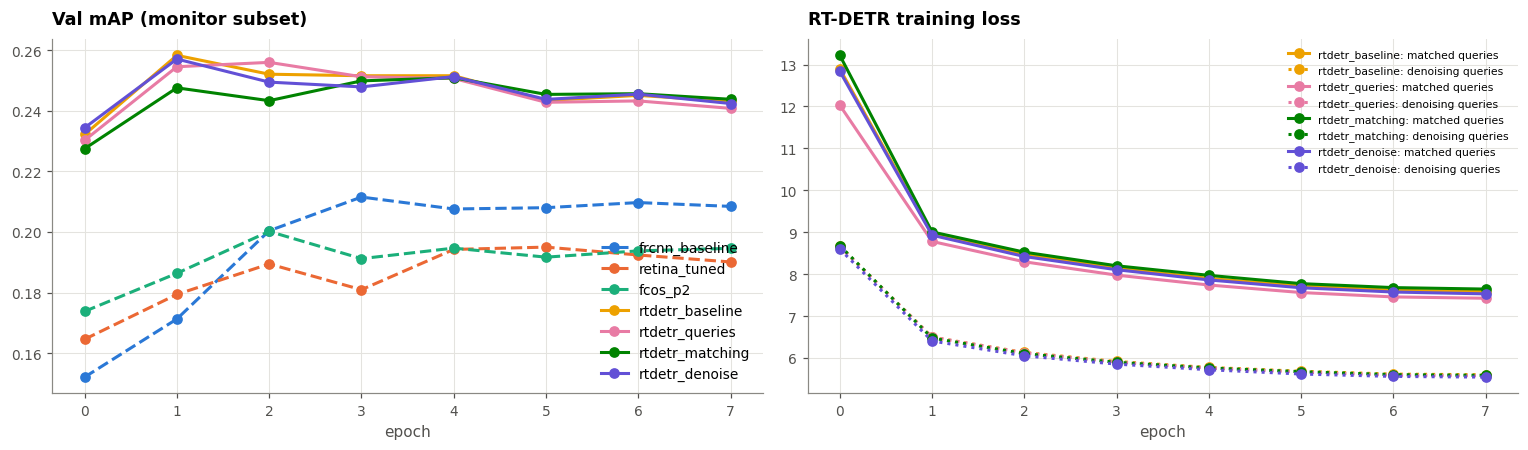

In [14]:
# Val mAP per epoch vs the CNN detectors; RT-DETR loss of matched vs denoising queries
META = {"epoch", "time", "lr", "train_min", "val_mAP", "val_AP50", "val_AP_small"}


def history(run_id):
    f = P.runs / run_id / "history.csv"
    return pd.read_csv(f if f.exists() else REPO_ROOT / "results/runs" / run_id / "history.csv")


rt_ids = [r for r in order if r.startswith("rtdetr")]
fig, (a0, a1) = plt.subplots(1, 2, figsize=(14, 4.2))
for r, col in zip(order, PALETTE):
    h = history(r)
    a0.plot(h.epoch, h.val_mAP, marker="o", color=col, ls="--" if r in cnn_ids else "-", label=r)
for r, col in zip(rt_ids, PALETTE[len(cnn_ids):]):
    h = history(r)
    main = h[[c for c in h.columns if c not in META and not c.startswith("dn_")]].sum(1)
    a1.plot(h.epoch, main, marker="o", color=col, label=f"{r}: matched queries")
    a1.plot(h.epoch, h[[c for c in h.columns if c.startswith("dn_")]].sum(1), marker="o", color=col, ls=":",
            label=f"{r}: denoising queries")
a0.set(title="Val mAP (monitor subset)", xlabel="epoch")
a0.legend(loc="lower right")
a1.set(title="RT-DETR training loss", xlabel="epoch")
a1.legend(fontsize=7)
fig.tight_layout()
save_fig(fig, "rtdetr_curves", P)

In [15]:
# Convergence within the budget: best epoch and the val mAP change over the last 3 epochs
rows = {}
for r in order:
    h = history(r)
    rows[r] = {"best epoch": int(h.loc[h.val_mAP.idxmax(), "epoch"]), "best monitor mAP": h.val_mAP.max(),
               "mAP change, last 3 epochs": h.val_mAP.iloc[-1] - h.val_mAP.iloc[-4]}
pd.DataFrame(rows).T.round(4)

,best epoch,best monitor mAP,"mAP change, last 3 epochs"
frcnn_baseline,3.0,0.2115,0.0009
retina_tuned,5.0,0.1950,-0.0041
fcos_p2,2.0,0.2002,-0.0001
rtdetr_baseline,1.0,0.2583,-0.0085
rtdetr_queries,2.0,0.2560,-0.0099
rtdetr_matching,4.0,0.2509,-0.0071
rtdetr_denoise,1.0,0.2571,-0.0089


**Duplicates and NMS.** A detector without NMS has to suppress duplicates itself. For each model, the
share of confident boxes (score ≥ 0.3) that overlap a more confident box of the same class with IoU ≥ 0.7,
and the val mAP after applying NMS (IoU 0.5) on top of the saved predictions. The CNN predictions are
available when the outputs of the earlier notebooks are attached as inputs.

In [16]:
# Duplicate boxes per model, and RT-DETR val mAP with NMS added
from torchvision.ops import batched_nms, box_iou

models = list(dict.fromkeys(cnn_ids + ["rtdetr_baseline", tuned_id]))
preds = {r: pd.read_csv(P.runs / r / "predictions" / "val.csv") for r in models
         if (P.runs / r / "predictions" / "val.csv").exists()}
for r in models:
    if r not in preds:
        print(f"{r}: no val predictions in {P.runs}")


def xyxy(g):
    b = torch.tensor(g[["x", "y", "w", "h"]].to_numpy(), dtype=torch.float32)
    return torch.cat([b[:, :2], b[:, :2] + b[:, 2:]], 1)


def duplicate_share(p, score=0.3, iou=0.7):
    dup = total = 0
    for _, g in p[p.score >= score].groupby(["file_name", "cls"]):
        g = g.sort_values("score", ascending=False)
        overlap = box_iou(xyxy(g), xyxy(g)).triu(diagonal=1)          # IoU with every more confident box
        dup += int((overlap.max(0).values >= iou).sum())
        total += len(g)
    return dup / max(total, 1)


def with_nms(p, iou=0.5):
    kept = [g.iloc[batched_nms(xyxy(g), torch.tensor(g.score.to_numpy(), dtype=torch.float32),
                         torch.tensor(g.cls.to_numpy()), iou).numpy()]
            for _, g in p.groupby("file_name")]
    return pd.concat(kept)


rows = {}
for r, p in preds.items():
    rows[r] = {"duplicates, % of boxes ≥ 0.3": 100 * duplicate_share(p), "val mAP": val.loc[r, "mAP"]}
    if r.startswith("rtdetr"):
        rows[r]["val mAP with NMS 0.5"] = evaluate(with_nms(p), val_frames, P.data, per_class=False)["mAP"]
pd.DataFrame(rows).T.round(4)

,"duplicates, % of boxes ≥ 0.3",val mAP,val mAP with NMS 0.5
frcnn_baseline,0.0000,0.2090,NaN
retina_tuned,0.0000,0.1942,NaN
fcos_p2,0.0000,0.1993,NaN
rtdetr_baseline,5.1461,0.2561,0.2551


**Small objects.** AP, AP50 and recall per object-size bin, using object sides √(w·h) in original pixels.

In [17]:
# AP, AP50 and recall per object-size bin (original pixels) from saved val predictions
pd.concat({r: evaluate_by_size(p, val_frames, P.data) for r, p in preds.items()},
          names=["run", "object side"]).round(4)

objects      AP    AP50  AR_500
run             object side                                 
frcnn_baseline  < 16 px          380  0.0096  0.0474  0.0342
                16–32 px       21530  0.0921  0.2421  0.2006
                32–96 px       79357  0.1829  0.3963  0.3887
                > 96 px        12865  0.4043  0.7005  0.6032
retina_tuned    < 16 px          380  0.0019  0.0113  0.0199
                16–32 px       21530  0.0751  0.2278  0.1864
                32–96 px       79357  0.1811  0.3858  0.3577
                > 96 px        12865  0.3358  0.5813  0.5699
fcos_p2         < 16 px          380  0.0087  0.0358  0.0396
                16–32 px       21530  0.0985  0.2533  0.2300
                32–96 px       79357  0.1844  0.3848  0.4112
                > 96 px        12865  0.3524  0.6066  0.6240
rtdetr_baseline < 16 px          380  0.0048  0.0185  0.0649
                16–32 px       21530  0.1464  0.4354  0.2822
                32–96 px       79357  0.2310  0.4744  0.4560
                > 96 px        12865  0.4395  0.7092  0.6118

**Dense scenes.** Val frames split by the number of annotated objects: AP per group, and the mean number
of confident detections (score ≥ 0.3) per frame against the mean number of objects.

In [18]:
# AP and confident detections per frame by scene density, from saved val predictions
n_val = val_frames.file_name.map(lambda f: len(targets[f]["boxes"]))
density = pd.cut(n_val, [-1, 20, 60, 1000], labels=["≤ 20 objects", "21–60", "> 60"])
rows = {}
for r, p in preds.items():
    confident = p[p.score >= 0.3].groupby("file_name").size()
    for d in density.cat.categories:
        fr = val_frames[density == d]
        m = evaluate(p[p.file_name.isin(fr.file_name)], fr, P.data, per_class=False)
        rows[(r, d)] = {"frames": len(fr), "objects per frame": n_val[density == d].mean(),
                        "detections ≥ 0.3 per frame": confident.reindex(fr.file_name, fill_value=0).mean(),
                        "mAP": m["mAP"], "AP50": m["AP50"], "AP_small": m["AP_small"]}
pd.DataFrame(rows).T.round(3)

frames  objects per frame  \
frcnn_baseline  ≤ 20 objects   977.0             13.876   
                21–60         1404.0             42.169   
                > 60           465.0             88.968   
retina_tuned    ≤ 20 objects   977.0             13.876   
                21–60         1404.0             42.169   
                > 60           465.0             88.968   
fcos_p2         ≤ 20 objects   977.0             13.876   
                21–60         1404.0             42.169   
                > 60           465.0             88.968   
rtdetr_baseline ≤ 20 objects   977.0             13.876   
                21–60         1404.0             42.169   
                > 60           465.0             88.968   

                              detections ≥ 0.3 per frame    mAP   AP50  \
frcnn_baseline  ≤ 20 objects                       5.907  0.122  0.208   
                21–60                             49.616  0.232  0.453   
                > 60                              87.434  0.272  0.570   
retina_tuned    ≤ 20 objects                       5.020  0.119  0.182   
                21–60                             59.612  0.215  0.418   
                > 60                             111.191  0.260  0.537   
fcos_p2         ≤ 20 objects                      53.114  0.109  0.164   
                21–60                            142.663  0.220  0.410   
                > 60                             179.157  0.255  0.524   
rtdetr_baseline ≤ 20 objects                       9.590  0.137  0.231   
                21–60                             95.104  0.284  0.508   
                > 60                             155.559  0.298  0.609   

                              AP_small  
frcnn_baseline  ≤ 20 objects     0.002  
                21–60            0.109  
                > 60             0.095  
retina_tuned    ≤ 20 objects     0.010  
                21–60            0.090  
                > 60             0.074  
fcos_p2         ≤ 20 objects     0.008  
                21–60            0.116  
                > 60             0.116  
rtdetr_baseline ≤ 20 objects     0.016  
                21–60            0.165  
                > 60             0.097